# BM25 field weighting: WANDS and HotpotQA

Does weighting document fields separately improve retrieval over concatenating their text?
This notebook defines two experiments with a shared scoring rule:

$$s(q,d)=\sum_f w_f\,\mathrm{BM25}_f(q,d).$$

Each field has its own IDF and length normalization. This is a weighted sum of independent
BM25 scores, **not BM25F**. We fix lowercase regex `\w+` tokenization with NLTK Porter stemming
(no stop-word removal), Lucene BM25 (`k1=1.2`, `b=0.75`), and weight levels `{0, 1, 2, 4}`.
Common-scale duplicates and the all-zero setting are removed. Selection maximizes mean nDCG@10;
all fields are scored over the full corpus before top-100 retrieval.

**Single-field BEIR datasets:** with only one nonempty field (for example, Quora's text), a positive
weight cannot change the ranking, so relative field-weight optimization does not apply.

| Experiment | Fields | Weight selection | Reported evaluation |
|---|---|---|---|
| WANDS | Name, category, description, class, features; also a three-field subset | Five seeds of two-way two-fold query CV | Out-of-fold (OOF) scores |
| HotpotQA (BEIR) | Title and text | Dev queries; CV on dev as a stability diagnostic | Frozen weights on test |

The evaluation protocols and relevance definitions differ: compare methods **within** each dataset,
not absolute scores across datasets. No improvement is assumed.

## Before running

This notebook is intentionally **unexecuted**: outputs and execution counts are empty.
Run the setup cell, then either dataset section in order. Each section has its own setup and helper
functions; they reuse variable names, so rerun a section from its beginning when switching datasets.
The code downloads missing HotpotQA data only when executed. WANDS requires local TSV files or the
project's dataset ZIP. Set `ROOT` below if the project cannot be detected automatically.

HotpotQA indexes the full corpus (about 5.23 million documents) on CPU. Memory-mapped cached scores
reduce reload costs, but index construction and vocabularies still require substantial RAM and disk.
Query caps reduce evaluation time, **not** corpus size. WANDS uses batched in-memory scoring;
HotpotQA processes one query at a time with disk-backed indexes.

Results are written under `results/field_weighting/{wands,hotpotqa}/` when run.

In [1]:
# Install in the active kernel if needed:
# %pip install "bm25s==0.3.16" numpy pandas scipy nltk matplotlib datasets pyarrow tqdm
from pathlib import Path
import json
from importlib.metadata import version

ROOT = None  # Or Path('/path/to/e2e-search-lab').
if ROOT is None:
    ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
                 if (p/'datasets').is_dir() or (p/'datasets.zip').is_file()), Path.cwd())
ROOT = Path(ROOT).expanduser().resolve()
OUTPUT = ROOT/'results/field_weighting'
PACKAGES = {p: version(p) for p in ['bm25s', 'nltk', 'numpy', 'pandas', 'scipy', 'datasets']}
print('Project:', ROOT, '| packages:', PACKAGES)

Project: /Users/eteper/Downloads/projects/e2e-search-lab | packages: {'bm25s': '0.3.16', 'nltk': '3.10.4', 'numpy': '2.5.2', 'pandas': '3.0.5', 'scipy': '1.18.1', 'datasets': '5.0.1'}


# WANDS: product retrieval

**Question:** WANDS describes every product with five text fields. Does giving each field its own BM25
index and weight beat indexing all of them as one document, and which fields carry the signal?

| Field | What it holds |
|---|---|
| `product_name` | short product title |
| `category hierarchy` | category path, e.g. `Furniture / Living Room Furniture / Console Tables` |
| `product_description` | free-text description |
| `product_class` | product type, e.g. `Sofa & Console Tables` |
| `product_features` | `key : value` attributes such as color, material and style |

The remaining columns (`rating_count`, `average_rating`, `review_count`) are numbers, not text, so they are excluded from this text-field experiment.

The tokenizer is **fixed (regex + Porter)** and every field gets its own BM25 index. Only the field
weights change:

$$s(q,d)=\sum_{f \in \text{fields}} w_f\,BM25_f(q,d).$$

We compare concatenated text, single fields, equal weights and tuned weights. To see which fields are
worth indexing, the same run also tunes a smaller field set: name, category and description only, without
the type label and the long attribute list. Note that this is a **sum of per-field BM25 scores**, each
with its own IDF and length normalization; it is **not BM25F**.

## 1. Setup and data

Use the shared setup cell above.

We use the tab-separated `product.csv`, `query.csv` and `label.csv` files from
[WANDS](https://github.com/wayfair/WANDS). The paths below are checked in order; change `DATA_DIR` /
`DATA_ZIP` if your copy lives elsewhere. The ZIP is read in place, without extraction; evaluation artifacts are saved after the analysis.

`FIELDS` lists every field to weight, and `SUBSET` is the smaller field set compared in the same run.
`product_features` is indexed as-is, so attribute keys such as `overallwidth` are indexed too; they appear
in most products and get a low IDF. The weight grid grows quickly with the number of fields: 4 levels and
5 fields give 781 distinct settings.

In [2]:
from pathlib import Path
from zipfile import ZipFile
from functools import lru_cache
from itertools import product
import gc
import re

import bm25s
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer
from IPython.display import display

DATA_DIR = ROOT/"datasets/wands"
DATA_ZIP = ROOT/"datasets.zip"  # ZIP member paths: datasets/wands/*.csv
# All five text fields in WANDS; the numeric columns (ratings, review counts) are not text.
FIELDS = ["product_name", "category hierarchy", "product_description",
          "product_class", "product_features"]
# A smaller field set tuned in the same run: no type label and no attribute list.
SUBSET = ["product_name", "category hierarchy", "product_description"]
LEVELS = (0, 1, 2, 4)  # 0 drops the field; a common scale factor does not change the ranking
SEEDS = (0, 1, 2, 3, 4)
BATCH_SIZE, K = 16, 100
BM25_PARAMS = dict(method="lucene", k1=1.2, b=0.75)
assert FIELDS and len(set(FIELDS)) == len(FIELDS)
assert set(SUBSET) < set(FIELDS), "SUBSET must be a proper subset of FIELDS."


def load_table(name):
    if (DATA_DIR / name).is_file():
        return pd.read_csv(DATA_DIR / name, sep="\t")
    if DATA_ZIP.is_file():
        with ZipFile(DATA_ZIP) as z, z.open(f"datasets/wands/{name}") as f:
            return pd.read_csv(f, sep="\t")
    raise FileNotFoundError(f"{name} not found: set DATA_DIR or DATA_ZIP.")


products = load_table("product.csv")
queries = load_table("query.csv")
labels = load_table("label.csv")
assert set(FIELDS) <= set(products.columns), "FIELDS contains an unknown column."
products[FIELDS] = products[FIELDS].fillna("").astype(str)
assert products.product_id.is_unique and queries.query_id.is_unique
assert len(products) >= K
pos = {str(pid): i for i, pid in enumerate(products.product_id)}
labels = labels.assign(
    qid=labels.query_id.astype(str),
    doc=labels.product_id.astype(str).map(pos),
    grade=labels.label.map({"Exact": 2, "Partial": 1, "Irrelevant": 0}),
)
assert labels[["doc", "grade"]].notna().all().all()
# Keep the highest grade if a (query, product) pair is labeled more than once.
labels = labels.groupby(["qid", "doc"], as_index=False).grade.max()
qrels = {qid: dict(zip(g.doc.astype(int), g.grade.astype(int)))
         for qid, g in labels.groupby("qid")}
# Only queries with at least one relevant (Exact or Partial) product can be evaluated.
queries = queries[queries.query_id.astype(str).map(
    lambda q: any(v > 0 for v in qrels.get(q, {}).values()))].reset_index(drop=True)
grades = [qrels[str(q)] for q in queries.query_id]
assert len(queries) >= 4
print(f"{len(products):,} products; {len(queries)} evaluable queries")
display(pd.DataFrame({"Field": FIELDS,
    "Empty (%)": [100 * products[f].str.strip().eq("").mean() for f in FIELDS],
    "Example": [products[f].iloc[0][:70] for f in FIELDS]}).round(2))

/opt/homebrew/anaconda3/envs/llm_optimization/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


42,994 products; 479 evaluable queries


,Field,Empty (%),Example
0,product_name,0.00,solid wood platform bed
1,category hierarchy,3.62,Furniture / Bedroom Furniture / Beds & Headboa...
2,product_description,13.97,"good , deep sleep can be quite difficult to ha..."
3,product_class,6.63,Beds
4,product_features,0.00,overallwidth-sidetoside:64.7|dsprimaryproducts...


## 2. Same tokenizer, separate field indexes

Every field uses the same regex + Porter tokenizer and Lucene BM25 parameters (k1 = 1.2, b = 0.75).
Empty field values are kept so that a product sits on the same row in every index.
Two concatenated baselines are indexed as well: all fields in one document, and `SUBSET` in one document.
Each query is scored against **all** products; there is no fusion step that depends on a top-k candidate pool.

In [3]:
porter = PorterStemmer()

@lru_cache(maxsize=200_000)
def stem(word):
    return porter.stem(word)


def tokenize(text):
    return [stem(t) for t in re.findall(r"\w+", text.lower())]


query_tokens = [tokenize(q) for q in queries["query"].astype(str)]


class FieldScorer:
    """BM25 for one field, scored as a sparse (query x term) @ (term x doc) product.

    Reuses bm25s' precomputed per-term document scores, so a whole batch of
    queries is scored with a single sparse matrix multiplication.
    """

    def __init__(self, token_lists, probe_queries):
        index = bm25s.BM25(**BM25_PARAMS)
        index.index(token_lists, show_progress=False)
        s = index.scores
        self.vocab = index.vocab_dict
        self.matrix = sp.csc_matrix(
            (s["data"], s["indices"], s["indptr"]),
            shape=(len(token_lists), len(s["indptr"]) - 1),
        ).T.tocsr()
        self.avg_len = np.mean([len(t) for t in token_lists])
        # Sanity check against the library: repeated terms, out-of-vocabulary and empty queries.
        probe = [probe_queries[0], probe_queries[0] * 2, ["__oov_probe__"], []]
        ref = np.stack([index.get_scores(t) if t else np.zeros(len(token_lists)) for t in probe])
        assert np.allclose(self.score(probe), ref, atol=1e-4)

    def score(self, token_lists):
        # Repeated query terms are counted twice, matching bm25s.get_scores.
        rows, cols = [], []
        for i, tokens in enumerate(token_lists):
            for t in tokens:
                j = self.vocab.get(t)
                if j is not None:
                    rows.append(i)
                    cols.append(j)
        q = sp.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)),
                          shape=(len(token_lists), self.matrix.shape[0]))
        return (q @ self.matrix).toarray()


CONCAT_ALL, CONCAT_SUBSET = "concat_all", "concat_subset"
sources = {**{f: products[f] for f in FIELDS},
           CONCAT_ALL: products[FIELDS].agg(" ".join, axis=1),
           CONCAT_SUBSET: products[SUBSET].agg(" ".join, axis=1)}
scorers, stats = {}, []
for name, texts in sources.items():
    scorers[name] = FieldScorer([tokenize(t) for t in texts], query_tokens)
    stats.append({"Index": name, "Avg. tokens": scorers[name].avg_len,
                  "Vocabulary": len(scorers[name].vocab)})
    print("Indexed:", name)
    gc.collect()
display(pd.DataFrame(stats).round(1))

Indexed: product_name
Indexed: category hierarchy
Indexed: product_description
Indexed: product_class
Indexed: product_features
Indexed: concat_all
Indexed: concat_subset


,Index,Avg. tokens,Vocabulary
0,product_name,6.5,25436
1,category hierarchy,8.3,1117
2,product_description,65.2,19827
3,product_class,2.2,629
4,product_features,150.8,22424
5,concat_all,233.1,51267
6,concat_subset,80.0,36756


## 3. Weight sweep and metrics

We sweep each weight over `{0, 1, 2, 4}` in `FIELDS` order. Vectors that are equal up to a common factor
rank identically, so they are deduplicated. Single-field, equal-weight and leave-one-field-out
(ablation) settings are all part of the grid, and so is every setting that gives the fields outside
`SUBSET` weight 0, which is the grid for the smaller field set. Scores are **not** normalized, so a weight
should be read together with the scale of that field's BM25 scores. Repeating a field's text is not the
same thing: it also changes term frequency and document length.

**nDCG@10:** Exact=2, Partial=1, gain `2**grade - 1`.
**MRR@10:** Exact only; queries with no Exact product are left out of the average.
**Recall@10/@100:** Exact + Partial. Unlabeled products count as irrelevant.
Ties are broken by the lower product row number; products with a zero score are not returned.

Scoring all settings takes a few minutes on a laptop.

In [4]:
# Weights are always in FIELDS order.
weight_grid = sorted({tuple(np.array(w, dtype=float) / max(w))
                      for w in product(LEVELS, repeat=len(FIELDS)) if max(w) > 0})
BASELINE, EQUAL = CONCAT_SUBSET, "equal"  # fixed reference: name + category + description
configs = {CONCAT_ALL: None, CONCAT_SUBSET: None, EQUAL: np.ones(len(FIELDS))}
configs.update({f"w{i:03d}": np.array(w) for i, w in enumerate(weight_grid)
                if len(set(w)) > 1})  # the all-equal vector is already EQUAL
TUNABLE = [s for s in configs if configs[s] is not None]
# Settings that give every field outside SUBSET weight 0: the smaller field set's grid.
outside = np.array([f not in SUBSET for f in FIELDS])
SUBSET_ONLY = [s for s in TUNABLE if not configs[s][outside].any()]
print(f"{len(TUNABLE)} weight settings ({len(SUBSET_ONLY)} use only {SUBSET}); "
      f"field order: {FIELDS}")


def topk(scores, k=K):
    # Resolve ties at the cutoff deterministically; pad missing results with -1.
    ranked = np.full((len(scores), k), -1, dtype=np.int32)
    for i, row in enumerate(scores):
        cutoff = np.partition(row, len(row) - k)[len(row) - k]
        above = np.flatnonzero(row > cutoff)
        tied = np.flatnonzero(row == cutoff)[:k - len(above)]
        ids = np.concatenate([above, tied])
        ids = ids[np.lexsort((ids, -row[ids]))]
        ids = ids[row[ids] > 0]
        ranked[i, :len(ids)] = ids
    return ranked


discounts = 1 / np.log2(np.arange(2, 12))
n_rel = np.array([sum(v > 0 for v in g.values()) for g in grades])
has_exact = np.array([2 in g.values() for g in grades])
idcg = np.array([np.dot(2.0 ** np.array(sorted(g.values(), reverse=True)[:10]) - 1,
                       discounts[:min(10, len(g))]) for g in grades])
METRICS = ["nDCG@10", "MRR@10", "Recall@10", "Recall@100"]


def evaluate(ranked):
    """Per-query metrics; MRR@10 is NaN for queries without an Exact product."""
    g = np.array([[rel.get(int(d), 0) for d in row] for row, rel in zip(ranked, grades)])
    exact = g[:, :10] == 2
    return {
        "nDCG@10": ((2.0 ** g[:, :10] - 1) * discounts).sum(1) / idcg,
        "MRR@10": np.where(has_exact, np.where(exact.any(1), 1 / (exact.argmax(1) + 1), 0), np.nan),
        "Recall@10": (g[:, :10] > 0).sum(1) / n_rel,
        "Recall@100": (g > 0).sum(1) / n_rel,
    }


# Score each field once per batch, then combine the cached scores for every weight setting.
rankings = {s: [] for s in configs}
for start in range(0, len(queries), BATCH_SIZE):
    batch = query_tokens[start:start + BATCH_SIZE]
    field_scores = [scorers[f].score(batch) for f in FIELDS]
    for concat in (CONCAT_ALL, CONCAT_SUBSET):
        rankings[concat].append(topk(scorers[concat].score(batch)))
    for system in TUNABLE:
        scores = np.zeros_like(field_scores[0])
        for weight, values in zip(configs[system], field_scores):
            if weight > 0:
                scores += weight * values
        rankings[system].append(topk(scores))
rankings = {s: np.concatenate(parts) for s, parts in rankings.items()}
per_query = {s: evaluate(r) for s, r in rankings.items()}

781 weight settings (37 use only ['product_name', 'category hierarchy', 'product_description']); field order: ['product_name', 'category hierarchy', 'product_description', 'product_class', 'product_features']


## 4. Comparison without selection bias

We use **5 seeds × two-way 2-fold** cross-validation. Each time, the weights are chosen by mean nDCG@10
on one half of the queries and measured on the other half; then the roles swap. Every query therefore
gets an out-of-fold (OOF) score from weights it did not help choose. Tuning is done twice on the same
splits: over all settings, and over the settings that use only `SUBSET`. The concatenated baselines and
equal weights are fixed references with nothing to tune.

Δ values use the predeclared three-field `SUBSET` concatenation as the reference. Both concatenated
baselines are reported; their relative strength is an empirical question. The seeds reuse the same queries, so the seed standard deviation
only shows sensitivity to the split; it is **not** a confidence interval. For that, the cell also reports
paired bootstrap 95% intervals over queries (OOF scores averaged over seeds). These descriptive
intervals hold the fitted fold choices fixed; they do not include uncertainty from repeating weight selection. The last row compares the two
tuned systems directly: what `product_class` and `product_features` add when every field can be weighted.

,nDCG@10,MRR@10,Recall@10,Recall@100,Δ nDCG (pp),nDCG seed std
Method,,,,,,
"Concatenated text, all 5 fields",0.6687,0.6979,0.0591,0.3734,-1.6435,0.0000
"Concatenated text, 3 fields",0.6852,0.7068,0.0602,0.3756,0.0000,0.0000
"Equal weights, all 5 fields",0.6861,0.6409,0.0613,0.3859,0.0967,0.0000
"Tuned, 3 fields (OOF)",0.7142,0.6856,0.0638,0.4082,2.8987,0.0015
"Tuned, all 5 fields (OOF)",0.7188,0.6952,0.0640,0.4114,3.3633,0.0037


,Pool,product_name,category hierarchy,product_description,product_class,product_features,Times selected
0,"Tuned, 3 fields (OOF)",1.0,0.50,0.25,0.00,0.00,7
1,"Tuned, 3 fields (OOF)",1.0,0.50,0.50,0.00,0.00,3
4,"Tuned, all 5 fields (OOF)",1.0,0.50,0.25,0.25,0.25,6
2,"Tuned, all 5 fields (OOF)",1.0,0.25,0.25,0.25,0.25,1
3,"Tuned, all 5 fields (OOF)",1.0,0.25,0.50,0.50,0.25,1
5,"Tuned, all 5 fields (OOF)",1.0,0.50,0.25,0.25,0.50,1
6,"Tuned, all 5 fields (OOF)",1.0,0.50,0.25,0.50,0.00,1


,Δ nDCG (pp),95% CI low,95% CI high,Wins,Losses
Comparison,,,,,
"Concatenated text, all 5 fields vs. Concatenated text, 3 fields",-1.64,-2.96,-0.29,149,203
"Equal weights, all 5 fields vs. Concatenated text, 3 fields",0.10,-1.67,1.94,185,184
"Tuned, 3 fields (OOF) vs. Concatenated text, 3 fields",2.90,1.22,4.58,205,166
"Tuned, all 5 fields (OOF) vs. Concatenated text, 3 fields",3.36,1.66,5.11,212,158
"Tuned, all 5 fields (OOF) vs. Tuned, 3 fields (OOF)",0.46,-0.16,1.11,166,139


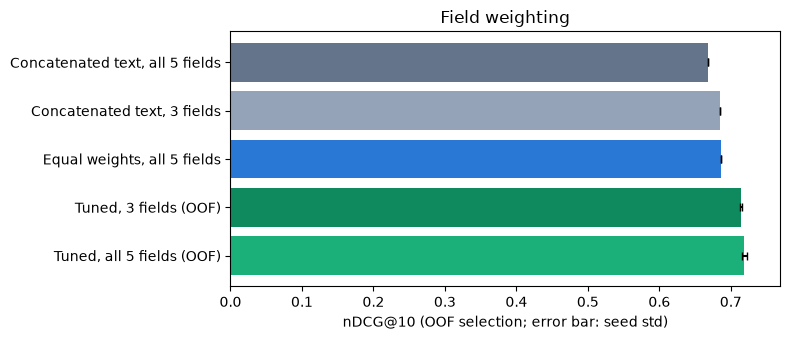

In [5]:
n_sub, n_all = len(SUBSET), len(FIELDS)
POOLS = {"oof_subset": SUBSET_ONLY, "oof_all": TUNABLE}
NAMES = {CONCAT_ALL: f"Concatenated text, all {n_all} fields",
         CONCAT_SUBSET: f"Concatenated text, {n_sub} fields",
         EQUAL: f"Equal weights, all {n_all} fields",
         "oof_subset": f"Tuned, {n_sub} fields (OOF)",
         "oof_all": f"Tuned, all {n_all} fields (OOF)"}
cv_rows, selections = [], []
oof_runs = {pool: {} for pool in POOLS}
chosen_runs = {pool: {} for pool in POOLS}
for seed in SEEDS:
    perm = np.random.default_rng(seed).permutation(len(queries))
    folds = np.array_split(perm, 2)
    for pool, systems in POOLS.items():
        oof = {m: np.full(len(queries), np.nan) for m in METRICS}
        chosen = np.empty(len(queries), dtype=object)
        for fold in range(2):
            tune, held = folds[fold], folds[1 - fold]
            best = max(systems, key=lambda s: per_query[s]["nDCG@10"][tune].mean())
            selections.append({"Pool": NAMES[pool], "Seed": seed, "Fold": fold,
                               **dict(zip(FIELDS, configs[best]))})
            chosen[held] = best
            for m in METRICS:
                oof[m][held] = per_query[best][m][held]
        oof_runs[pool][seed], chosen_runs[pool][seed] = oof, chosen
    results = {s: per_query[s] for s in (CONCAT_ALL, CONCAT_SUBSET, EQUAL)}
    results.update({pool: oof_runs[pool][seed] for pool in POOLS})
    for key, values in results.items():
        cv_rows.append({"Seed": seed, "Method": NAMES[key],
                        **{m: np.nanmean(values[m]) for m in METRICS},
                        "Δ nDCG (pp)": 100 * (values["nDCG@10"] - per_query[BASELINE]["nDCG@10"]).mean()})
cv = pd.DataFrame(cv_rows)
summary = cv.groupby("Method", sort=False)[METRICS + ["Δ nDCG (pp)"]].mean()
summary["nDCG seed std"] = cv.groupby("Method")["nDCG@10"].std()
display(summary.round(4))
selection_df = pd.DataFrame(selections)
display(selection_df.groupby(["Pool", *FIELDS]).size().rename("Times selected").reset_index()
        .sort_values(["Pool", "Times selected"], ascending=[True, False]))

# Paired bootstrap over queries: is each nDCG@10 change larger than query-sampling noise?
ndcg = {s: per_query[s]["nDCG@10"] for s in (CONCAT_ALL, CONCAT_SUBSET, EQUAL)}
ndcg.update({pool: np.mean([oof_runs[pool][s]["nDCG@10"] for s in SEEDS], axis=0) for pool in POOLS})
rng = np.random.default_rng(0)
boot_idx = rng.integers(0, len(queries), size=(10_000, len(queries)))
ci_rows = []
for a, b in [(CONCAT_ALL, BASELINE), (EQUAL, BASELINE), ("oof_subset", BASELINE),
             ("oof_all", BASELINE), ("oof_all", "oof_subset")]:
    diff = 100 * (ndcg[a] - ndcg[b])
    lo, hi = np.percentile(diff[boot_idx].mean(1), [2.5, 97.5])
    ci_rows.append({"Comparison": f"{NAMES[a]} vs. {NAMES[b]}", "Δ nDCG (pp)": diff.mean(),
                    "95% CI low": lo, "95% CI high": hi,
                    "Wins": (diff > 0).sum(), "Losses": (diff < 0).sum()})
display(pd.DataFrame(ci_rows).set_index("Comparison").round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(summary.index[::-1], summary["nDCG@10"][::-1], xerr=summary["nDCG seed std"][::-1],
        color=["#1baf7a", "#0f8a5f", "#2a78d6", "#94a3b8", "#64748b"], capsize=3)
ax.set(xlabel="nDCG@10 (OOF selection; error bar: seed std)", title="Field weighting",
       xlim=(0, min(1, summary["nDCG@10"].max() + 0.05)))
plt.tight_layout()
plt.show()

## 5. Which field contributes?

The single-field and ablation table below is **exploratory**: it shows fixed settings evaluated on all
queries, so it must not be read as a tuned result like the OOF table above. In each ablation, the
removed field gets weight 0 and the remaining fields keep equal weights.

After the table, we look at the queries with the largest gains and losses of the all-field OOF system
against the baseline for the first seed, each ranked with its own held-out weights, and show the top 3
results of both.

In [6]:
ablations = {NAMES[s]: s for s in (CONCAT_ALL, CONCAT_SUBSET, EQUAL)}
for i, field in enumerate(FIELDS):
    single = np.zeros(len(FIELDS)); single[i] = 1
    without = np.ones(len(FIELDS)); without[i] = 0
    for name, weights in [(f"Only {field}", single), (f"Without {field}", without)]:
        match = next((s for s in TUNABLE if np.array_equal(configs[s], weights)), None)
        if match is not None:
            ablations[name] = match
display(pd.DataFrame([
    {"Experiment": name, **{m: np.nanmean(per_query[s][m]) for m in METRICS}}
    for name, s in ablations.items()
]).set_index("Experiment").round(4))

# OOF gains/losses for the first seed: every query uses its own held-out weights.
SHOW = ["product_name", "product_class", "category hierarchy"]  # short fields that fit in a table
seed, pool = SEEDS[0], "oof_all"
delta = oof_runs[pool][seed]["nDCG@10"] - per_query[BASELINE]["nDCG@10"]
for title, indices in [("Largest gains", np.argsort(-delta)),
                       ("Largest losses", np.argsort(delta))]:
    print("\n" + title)
    for qi in indices[:2]:
        system = chosen_runs[pool][seed][qi]
        print(f"\n{queries.iloc[qi]['query']} | Δ nDCG={delta[qi]:+.3f}")
        print("Weights:", dict(zip(FIELDS, configs[system].tolist())))
        rows = []
        for name, s in [("concat (3 fields)", BASELINE), ("OOF (all fields)", system)]:
            for rank, d in enumerate(rankings[s][qi, :3], 1):
                if d >= 0:
                    rows.append({"Method": name, "Rank": rank, "Label": grades[qi].get(int(d), 0),
                                 **{f: products.iloc[d][f][:70] for f in SHOW}})
        display(pd.DataFrame(rows))

,nDCG@10,MRR@10,Recall@10,Recall@100
Experiment,,,,
"Concatenated text, all 5 fields",0.6687,0.6979,0.0591,0.3734
"Concatenated text, 3 fields",0.6852,0.7068,0.0602,0.3756
"Equal weights, all 5 fields",0.6861,0.6409,0.0613,0.3859
Only product_name,0.6671,0.6576,0.0617,0.3856
Without product_name,0.5736,0.5135,0.0504,0.3115
Only category hierarchy,0.2671,0.1673,0.0241,0.1730
Without category hierarchy,0.6869,0.6472,0.0614,0.3842
Only product_description,0.5297,0.5256,0.0469,0.2369
Without product_description,0.6657,0.6359,0.0595,0.3844



Largest gains

olive green console table | Δ nDCG=+0.890
Weights: {'product_name': 1.0, 'category hierarchy': 0.5, 'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.5}


,Method,Rank,Label,product_name,product_class,category hierarchy
0,concat (3 fields),1,0,george oliver mid-century tv stand with 2 stor...,TV Stands & Entertainment Centers,Furniture / Living Room Furniture / TV Stands ...
1,concat (3 fields),2,0,george oliver mid-century tv stand with 2 stor...,TV Stands & Entertainment Centers,Furniture / Living Room Furniture / TV Stands ...
2,concat (3 fields),3,1,durdham park console table,Sofa & Console Tables,Furniture / Living Room Furniture / Console Ta...
3,OOF (all fields),1,1,bouldin console table sofa table console tables,Sofa & Console Tables,Furniture / Living Room Furniture / Console Ta...
4,OOF (all fields),2,1,olive coffee table,Coffee & Cocktail Tables,Furniture / Living Room Furniture / Coffee Tab...
5,OOF (all fields),3,1,fabius console table,Sofa & Console Tables,Furniture / Living Room Furniture / Console Ta...



outdoor sectional doning | Δ nDCG=+0.767
Weights: {'product_name': 1.0, 'category hierarchy': 0.5, 'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.5}


,Method,Rank,Label,product_name,product_class,category hierarchy
0,concat (3 fields),1,0,caspian patio sectional with cushion,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...
1,concat (3 fields),2,0,arshleen patio sofa with cushions,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...
2,concat (3 fields),3,0,murph teal/gray indoor/outdoor area rug,Area Rugs,Rugs / Area Rugs
3,OOF (all fields),1,1,tahoe outdoor wicker patio sectional with cush...,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...
4,OOF (all fields),2,1,montclaire outdoor patio sectional with cushions,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...
5,OOF (all fields),3,1,catalina outdoor right arm sectional piece wit...,Patio Sofas,Outdoor / Outdoor & Patio Furniture / Outdoor ...



Largest losses

glass doors for bath | Δ nDCG=-0.844
Weights: {'product_name': 1.0, 'category hierarchy': 0.5, 'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.25}


,Method,Rank,Label,product_name,product_class,category hierarchy
0,concat (3 fields),1,2,fluence 59.63 '' x 58.31 '' bypass bath door,Shower & Tub Doors,Home Improvement / Bathroom Remodel & Bathroom...
1,concat (3 fields),2,2,fluence 59.63 '' x 58.31 '' bypass bath door w...,Shower & Tub Doors,Home Improvement / Bathroom Remodel & Bathroom...
2,concat (3 fields),3,2,fluence 52 '' x 63 '' bypass bath door with cl...,Shower & Tub Doors,Home Improvement / Bathroom Remodel & Bathroom...
3,OOF (all fields),1,0,glass wood french doors,Interior Doors,Home Improvement / Doors & Door Hardware / Int...
4,OOF (all fields),2,0,lucia glass french doors,Interior Doors,Home Improvement / Doors & Door Hardware / Int...
5,OOF (all fields),3,0,quadro glass french doors,Interior Doors,Home Improvement / Doors & Door Hardware / Int...



bathroom vanity knobs | Δ nDCG=-0.708
Weights: {'product_name': 1.0, 'category hierarchy': 0.5, 'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.25}


,Method,Rank,Label,product_name,product_class,category hierarchy
0,concat (3 fields),1,2,damask™ mushroom knob,Cabinet and Drawer Knobs,Home Improvement / Hardware / Cabinet Hardware...
1,concat (3 fields),2,2,deco 1/4 '' length square knob,Cabinet and Drawer Knobs,Home Improvement / Hardware / Cabinet Hardware...
2,concat (3 fields),3,2,deco 1 1/4 '' length square knob,Cabinet and Drawer Knobs,Home Improvement / Hardware / Cabinet Hardware...
3,OOF (all fields),1,0,esterly 32 '' single bathroom vanity,Vanities,Home Improvement / Bathroom Remodel & Bathroom...
4,OOF (all fields),2,0,ruvalcaba 32 '' single bathroom vanity set,Vanities,Home Improvement / Bathroom Remodel & Bathroom...
5,OOF (all fields),3,0,pichardo transitional 84 '' double bathroom va...,Vanities,Home Improvement / Bathroom Remodel & Bathroom...


### Reading the results

- **Concatenated → equal fields:** the effect of splitting the fields, which changes IDF and length normalization.
- **Equal fields → tuned OOF:** what weight selection adds on top. If nDCG goes up while Recall@100 goes
  down, the candidate coverage may be shrinking.
- **Tuned, 3 fields → tuned, all fields:** what `product_class` and `product_features` add when every field
  can be weighted.
- If the selected weights change across seeds/folds, any claim of a single "best" weight is weak.
- Query examples illustrate individual cases; they do not establish a general explanation.

No improvement is assumed. The results depend on these queries and labels; other tokenizers, per-field
`b` tuning, BM25F and cleaning the `product_features` keys are out of scope for this experiment.
Re-run the notebook if you change `FIELDS`.



In [7]:
folder = OUTPUT/'wands'
folder.mkdir(parents=True, exist_ok=True)
summary.to_csv(folder/'oof_summary.csv')
cv.to_csv(folder/'oof_by_seed.csv', index=False)
selection_df.to_csv(folder/'fold_weights.csv', index=False)
pd.DataFrame(stats).to_csv(folder/'field_stats.csv', index=False)
pd.DataFrame(ci_rows).to_csv(folder/'paired_intervals.csv', index=False)
pd.DataFrame([{'setting': s, **dict(zip(FIELDS, configs[s])),
               **{m: float(np.nanmean(per_query[s][m])) for m in METRICS}}
              for s in TUNABLE]).to_csv(folder/'exploratory_weight_grid.csv', index=False)
records = []
for seed in SEEDS:
    for method in [CONCAT_ALL, CONCAT_SUBSET, EQUAL, *POOLS]:
        values = oof_runs[method][seed] if method in POOLS else per_query[method]
        for qi, qid in enumerate(queries.query_id):
            records.append({'seed': seed, 'method': method, 'query_id': str(qid),
                            **{m: values[m][qi] for m in METRICS}})
pd.DataFrame(records).to_csv(folder/'oof_per_query.csv', index=False)
(folder/'manifest.json').write_text(json.dumps({
    'dataset': 'wands', 'fields': FIELDS, 'subset': SUBSET, 'levels': LEVELS,
    'seeds': SEEDS, 'bm25': BM25_PARAMS, 'packages': PACKAGES,
    'selection_metric': 'nDCG@10', 'evaluation': 'repeated two-fold query OOF',
    'baseline': BASELINE, 'query_ids': queries.query_id.astype(str).tolist(),
    'corpus_rows': len(products), 'k': K,
}, indent=2))
print('Saved:', folder)
# Release WANDS score matrices before building the much larger HotpotQA indexes.
del scorers, sources, field_scores, rankings, per_query, products
stem.cache_clear()
gc.collect()

Saved: /Users/eteper/Downloads/projects/e2e-search-lab/results/field_weighting/wands


33

# HotpotQA: title and passage retrieval

HotpotQA has title and text fields, enabling seven distinct relative weight settings.
Use local `datasets/hotpotqa/{corpus,queries,qrels_dev,qrels_test}.parquet`, or let the loader
fetch missing data from the BeIR Hugging Face repositories when run. Keep the full corpus.

## 1. HotpotQA configuration

The final weights are selected on dev and frozen before test scoring. Dev cross-validation
reports selection stability; it is not the final test result.


In [8]:
# Install in the active kernel if needed:
# %pip install "bm25s==0.3.16" numpy pandas scipy nltk datasets pyarrow tqdm
from pathlib import Path
from array import array
from functools import lru_cache
from itertools import product
from importlib.metadata import version
import gc, hashlib, json, re
import numpy as np
import pandas as pd
import bm25s
from datasets import Dataset, load_dataset
from nltk.stem import PorterStemmer
from tqdm.auto import tqdm
from IPython.display import display

DATASETS, FIELDS = ['hotpotqa'], ['title', 'text']
LEVELS, SEEDS, K = (0, 1, 2, 4), (0, 1, 2, 3, 4), 100
BM25_PARAMS = dict(method='lucene', k1=1.2, b=0.75)
MAX_DEV_QUERIES, MAX_TEST_QUERIES = None, None  # Optional deterministic query samples.
CHUNK = 4096
OUTPUT = ROOT/'results/field_weighting'
CACHE = OUTPUT/'indexes'
CACHE.mkdir(parents=True, exist_ok=True)
PACKAGES = {p: version(p) for p in ['bm25s', 'nltk', 'numpy', 'pandas', 'datasets']}
METRICS = ['nDCG@10', 'MRR@10', 'Recall@10', 'Recall@100']
assert set(DATASETS) <= {'hotpotqa'} and K >= 100 and SEEDS and CHUNK > 0
assert LEVELS and all(w >= 0 for w in LEVELS) and any(w > 0 for w in LEVELS)
assert all(v is None or v >= 4 for v in [MAX_DEV_QUERIES, MAX_TEST_QUERIES])
print('Root:', ROOT, '| packages:', PACKAGES)

Root: /Users/eteper/Downloads/projects/e2e-search-lab | packages: {'bm25s': '0.3.16', 'nltk': '3.10.4', 'numpy': '2.5.2', 'pandas': '3.0.5', 'datasets': '5.0.1'}


## 2. Load dev and test without reducing the corpus

BEIR query/document self-matches are excluded from rankings. Judgments are retained, following the
BEIR evaluation convention. Only IDs needed for judgments and self-exclusion are mapped to corpus rows.
Dev and test query IDs must be disjoint. Corpus statistics may use all documents, as in standard retrieval;
relevance labels are used only for selecting weights on dev and measuring frozen systems on test.

In [9]:
def load_beir(name):
    folder = ROOT/'datasets'/name
    if (folder/'corpus.parquet').exists():
        corpus = Dataset.from_parquet(str(folder/'corpus.parquet'))
        queries = pd.read_parquet(folder/'queries.parquet')
        rels = {s: pd.read_parquet(folder/f'qrels_{s}.parquet') for s in ['dev','test']}
    else:
        corpus = load_dataset(f'BeIR/{name}', 'corpus', split='corpus')
        queries = load_dataset(f'BeIR/{name}', 'queries', split='queries').to_pandas()
        rels = {s: pd.read_csv(f'https://huggingface.co/datasets/BeIR/{name}-qrels/resolve/main/{s}.tsv',
                              sep='\t', dtype={'query-id': str, 'corpus-id': str}) for s in ['dev','test']}
    query_map = dict(zip(queries['_id'].astype(str), queries['text'].fillna('').astype(str)))
    splits = {}
    for split, rel in rels.items():
        assert rel['score'].notna().all()
        rel['query-id'], rel['corpus-id'] = rel['query-id'].astype(str), rel['corpus-id'].astype(str)
        rel = rel.groupby(['query-id','corpus-id'], as_index=False)['score'].max()
        qrels = {q: dict(zip(g['corpus-id'], g['score'].astype(int))) for q,g in rel.groupby('query-id', sort=False)}
        qids = [q for q,g in qrels.items() if any(v > 0 for v in g.values())]
        assert qids and set(qids) <= query_map.keys()
        splits[split] = {'qids': qids, 'qrels': qrels}
    assert set(splits['dev']['qids']).isdisjoint(splits['test']['qids']), 'Dev/test query overlap.'
    for split, cap in [('dev',MAX_DEV_QUERIES),('test',MAX_TEST_QUERIES)]:
        qids = splits[split]['qids']
        if cap is not None and len(qids) > cap:
            ix = sorted(np.random.default_rng(0).choice(len(qids), cap, replace=False))
            splits[split]['qids'] = [qids[i] for i in ix]
    needed = {d for s in splits.values() for q in s['qids'] for d in s['qrels'][q]}
    needed.update(q for s in splits.values() for q in s['qids'])
    positions = {}
    for start in range(0, len(corpus), CHUNK):
        for offset, doc in enumerate(corpus[start:start+CHUNK]['_id']):
            doc = str(doc)
            if doc in needed:
                assert doc not in positions, 'Duplicate corpus ID.'
                positions[doc] = start+offset
    for data in splits.values():
        assert all(d in positions for q in data['qids'] for d,v in data['qrels'][q].items() if v > 0)
        data['grades'] = [{positions[d]:v for d,v in data['qrels'][q].items() if d in positions} for q in data['qids']]
        data['queries'] = [query_map[q] for q in data['qids']]
        data['excluded'] = [positions.get(q,-1) for q in data['qids']]
        del data['qrels']
    return corpus, splits

## 3. Separate indexes and a concatenated baseline

Empty documents remain on the same row in each field, preserving each field's own average length.
Token-empty fields are detected before constructing BM25, avoiding an all-empty-index division by zero.
If only one field is active, concatenation has identical tokens and reuses that field's index.
Weights act on raw BM25 scores; no score normalization or repeated field text is used.

In [10]:
porter = PorterStemmer()

@lru_cache(maxsize=200_000)
def stem(word):
    return porter.stem(word)


def tokenize(text):
    return [stem(t) for t in re.findall(r'\w+', text.lower())]


def text_batch(batch, fields):
    return [' '.join(str(v or '') for v in row).strip() for row in zip(*(batch[f] for f in fields))]


def build_index(name, corpus, fields):
    config = {'corpus': corpus._fingerprint, 'rows': len(corpus), 'fields': fields,
              'bm25': BM25_PARAMS, 'tokenizer': r'lowercase regex \w+ + NLTK Porter default', 'packages': PACKAGES}
    key = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:20]
    folder = CACHE/name/key
    meta = folder/'metadata.json'
    if meta.exists():
        saved = json.loads(meta.read_text())
        if saved['config'] == config:
            if not saved['stats']['active']:
                return None, saved['stats']
            return bm25s.BM25.load(str(folder), mmap=True, show_progress=False), saved['stats']
    vocab, ids, total, empty = {}, [], 0, 0
    empty_ids = array('I')
    for start in tqdm(range(0,len(corpus),CHUNK), desc=f"{name}: tokenizing {'+'.join(fields)}"):
        for text in text_batch(corpus[start:start+CHUNK], fields):
            terms = tokenize(text)
            total += len(terms); empty += not terms
            ids.append(array('I', (vocab.setdefault(t,len(vocab)) for t in terms)) if terms else empty_ids)
    stats = {'fields': fields, 'active': bool(vocab), 'avg_tokens': total/len(corpus),
             'empty_pct': 100*empty/len(corpus), 'vocabulary': len(vocab)}
    folder.mkdir(parents=True, exist_ok=True)
    if vocab:
        index = bm25s.BM25(**BM25_PARAMS)
        index.index(bm25s.tokenization.Tokenized(ids,vocab), show_progress=True)
        index.save(str(folder), show_progress=False)
        del index
    del ids, vocab
    stem.cache_clear();gc.collect()
    meta.write_text(json.dumps({'config':config,'stats':stats}, indent=2))
    model = bm25s.BM25.load(str(folder), mmap=True, show_progress=False) if stats['active'] else None
    return model, stats


def prepare_indexes(name, corpus):
    models, stats = {}, []
    for field in FIELDS:
        models[field], info = build_index(name, corpus, [field]);stats.append(info)
    active = [f for f in FIELDS if models[f] is not None]
    assert active, 'All document fields are token-empty.'
    if len(active) == 1:
        models['concat'] = models[active[0]]
        print(f'{name}: only {active[0]} is active; relative field-weight tuning is skipped.')
    else:
        models['concat'], info = build_index(name, corpus, FIELDS);stats.append(info)
    grid = sorted({tuple(np.array(w,dtype=float)/max(w)) for w in product(LEVELS,repeat=len(active)) if max(w)>0})
    configs = {f'w{i}': {f: (w[active.index(f)] if f in active else 0.0) for f in FIELDS}
               for i,w in enumerate(grid)}
    equal = next(k for k,w in configs.items() if all(w[f] == 1.0 for f in active))
    return models, pd.DataFrame(stats), active, configs, equal

## 4. Score every document, then measure relevance

There is no top-k candidate fusion: field scores are combined over the entire corpus before top-100
selection. Zero scores are omitted; cutoff ties favor the lower document row. For BEIR, nDCG and MRR
use positive relevance labels; recall counts all positive judgments. Unjudged documents score zero.
Only one query's dense document-score arrays are held at a time, so grid scoring does not allocate a
`queries × documents × settings` tensor.

In [11]:
def topk(scores):
    valid = np.flatnonzero(np.isfinite(scores) & (scores > 0))
    k = min(K,len(valid))
    if not k:
        return np.full(K,-1,dtype=np.int32)
    cutoff = np.partition(scores[valid],len(valid)-k)[len(valid)-k]
    above = valid[scores[valid] > cutoff]
    tied = valid[scores[valid] == cutoff][:k-len(above)]
    ids = np.concatenate([above,tied]);ids = ids[np.lexsort((ids,-scores[ids]))]
    return np.pad(ids,(0,K-len(ids)),constant_values=-1).astype(np.int32)


def evaluate(ranked, data):
    out = np.zeros((len(ranked),len(METRICS)))
    discounts = 1/np.log2(np.arange(2,12))
    for qi,ids in enumerate(ranked):
        relevant = {d for d,v in data['grades'][qi].items() if v > 0}
        assert relevant
        hits = np.array([int(d) in relevant if d >= 0 else False for d in ids])
        idcg = discounts[:min(10,len(relevant))].sum()
        rr = next((1/r for r,hit in enumerate(hits[:10],1) if hit),0.0)
        out[qi] = [np.dot(hits[:10],discounts)/idcg,rr,hits[:10].sum()/len(relevant),hits.sum()/len(relevant)]
    return out


def score_systems(models, configs, data, n_docs):
    ranked = {s: np.full((len(data['qids']),K),-1,dtype=np.int32) for s in configs}
    for qi,text in enumerate(tqdm(data['queries'],desc='Scoring queries')):
        tokens = tokenize(text)
        cache = {}
        for name,index in models.items():
            if index is not None and id(index) not in cache:
                known = [t for t in tokens if t in index.vocab_dict]
                cache[id(index)] = index.get_scores(known) if known else np.zeros(n_docs,dtype=np.float32)
        field_scores = {f:cache[id(models[f])] for f in FIELDS if models[f] is not None}
        for name,weights in configs.items():
            if weights is None:
                scores = cache[id(models['concat'])].copy()
            else:
                scores = np.zeros(n_docs,dtype=np.float32)
                for f,w in weights.items():
                    if w > 0:
                        scores += w*field_scores[f]
            if data['excluded'][qi] >= 0:
                scores[data['excluded'][qi]] = -np.inf
            ranked[name][qi] = topk(scores)
    return {s:evaluate(r,data) for s,r in ranked.items()},ranked

## 5. Dev selection, OOF diagnostics and a frozen test comparison

Dev cross-validation mirrors the WANDS notebook: select by mean nDCG@10 on one half, evaluate on the
other, swap, and repeat five seeds. This diagnoses sensitivity to dev-query splits. The final weights
are selected once on **all dev queries**, then frozen before test scoring. Test evaluates only the
concatenated baseline, equal fields and that selected setting.

If only one field contains tokens, no CV selection is reported as optimization.
The test delta against concatenation should be zero. Per-query test files permit later paired analysis.

In [ ]:
def choose_on_dev(per_query, configs, active):
    best = max(configs, key=lambda s:per_query[s][:,0].mean())
    selections, oof_runs = [], []
    if len(active) > 1:
        n = len(per_query[best]);assert n >= 4
        for seed in SEEDS:
            folds = np.array_split(np.random.default_rng(seed).permutation(n),2)
            oof = np.full((n,len(METRICS)),np.nan)
            for i in range(2):
                tune,held = folds[i],folds[1-i]
                chosen = max(configs,key=lambda s:per_query[s][tune,0].mean())
                oof[held] = per_query[chosen][held]
                selections.append({'seed':seed,'held_fold':1-i,**configs[chosen]})
            assert np.isfinite(oof).all()
            oof_runs.append(oof)
    return best,pd.DataFrame(selections,columns=['seed','held_fold',*FIELDS]),oof_runs


all_test = []
for name in DATASETS:
    corpus,splits = load_beir(name)
    models,field_stats,active,configs,equal = prepare_indexes(name,corpus)
    folder = OUTPUT/name;folder.mkdir(parents=True,exist_ok=True)
    print(f"\n{name}: {len(corpus):,} documents; {len(splits['dev']['qids']):,} dev / {len(splits['test']['qids']):,} test queries")
    display(field_stats)
    dev,dev_ranked = score_systems(models,{'concat':None,**configs},splits['dev'],len(corpus))
    del dev_ranked
    dev_grid = pd.DataFrame([{'setting':s,**w,**dict(zip(METRICS,dev[s].mean(0)))} for s,w in configs.items()])
    display(dev_grid.sort_values('nDCG@10',ascending=False).round(4))
    selected,folds,oof = choose_on_dev(dev,configs,active)
    dev_rows = [{'method':'Concatenated',**dict(zip(METRICS,dev['concat'].mean(0)))},
                {'method':'Equal fields',**dict(zip(METRICS,dev[equal].mean(0)))}]
    if oof:
        dev_rows.append({'method':'Tuned OOF (dev)',**dict(zip(METRICS,np.mean(oof,axis=0).mean(0)))})
    dev_summary = pd.DataFrame(dev_rows)
    display(dev_summary.round(4))
    print('Frozen weights selected on dev:',configs[selected])
    # No test scores/labels are passed into choose_on_dev().
    test_weights = {'Concatenated':None,'Equal fields':configs[equal],
                    'Dev-selected' if len(active)>1 else f'{active[0].capitalize()} only (no tuning)':configs[selected]}
    test,test_ranked = score_systems(models,test_weights,splits['test'],len(corpus))
    rows,per_query = [],[]
    for method,values in test.items():
        rows.append({'dataset':name,'method':method,**dict(zip(METRICS,values.mean(0))),
                     'delta_nDCG_pp':100*(values[:,0]-test['Concatenated'][:,0]).mean()})
        for qi,qid in enumerate(splits['test']['qids']):
            per_query.append({'method':method,'query_id':qid,'query':splits['test']['queries'][qi],
                              **dict(zip(METRICS,values[qi]))})
    test_summary = pd.DataFrame(rows);all_test.extend(rows)
    display(test_summary.round(4))
    field_stats.to_csv(folder/'field_stats.csv',index=False)
    dev_grid.to_csv(folder/'dev_weight_grid.csv',index=False)
    dev_summary.to_csv(folder/'dev_summary.csv',index=False)
    folds.to_csv(folder/'dev_fold_weights.csv',index=False)
    test_summary.to_csv(folder/'test_summary.csv',index=False)
    pd.DataFrame(per_query).to_csv(folder/'test_per_query.csv',index=False)
    np.savez_compressed(folder/'test_rankings.npz',**{f'system_{i}':r for i,r in enumerate(test_ranked.values())})
    manifest = {'dataset':name,'corpus_rows':len(corpus),'corpus_fingerprint':corpus._fingerprint,
                'fields':FIELDS,'active_fields':active,'relative_tuning_possible':len(active)>1,
                'levels':LEVELS,'seeds':SEEDS,'bm25':BM25_PARAMS,'packages':PACKAGES,
                'selected_on':'dev','selected_weights':configs[selected],
                'selection_metric':'nDCG@10','max_dev_queries':MAX_DEV_QUERIES,'max_test_queries':MAX_TEST_QUERIES,
                'dev_query_ids':splits['dev']['qids'],'test_query_ids':splits['test']['qids'],
                'test_system_order':list(test_ranked),'k':K}
    (folder/'manifest.json').write_text(json.dumps(manifest,indent=2))
    del models,corpus,splits,dev,test,test_ranked,oof
    stem.cache_clear();gc.collect()

summary = pd.DataFrame(all_test)
summary.to_csv(OUTPUT/'hotpotqa_test_summary.csv',index=False)
display(summary.round(4))
print('Saved:',OUTPUT)

## Reading the output

- `field_stats.csv`: which fields actually contain searchable tokens.
- `dev_weight_grid.csv`: all distinct field weight settings, scored on dev (exploratory).
- `dev_fold_weights.csv` and `dev_summary.csv`: dev OOF diagnostics; empty fold table when tuning is impossible.
- `test_summary.csv` and `test_per_query.csv`: final comparison using weights selected without test labels.
- `manifest.json`: selected weights, query splits, corpus fingerprint and parameters.

Changing field weights also changes the score contribution of each independently normalized index.
Equal fields and concatenated text are different baselines. A gain on dev does not establish a test gain;
use the saved per-query test results to examine uncertainty and individual wins/losses.

## Artifacts and interpretation

WANDS saves OOF summaries, per-seed and per-query scores, fold weights, field statistics,
exploratory grid scores and paired intervals. HotpotQA saves dev diagnostics and frozen test results,
including test rankings. Both save configuration manifests.

Use WANDS OOF results and HotpotQA test results for the main comparison. Full-query WANDS grid scores
and HotpotQA dev-grid scores describe selection candidates, not independently measured tuned gains.
Inspect nDCG alongside recall and selected-weight stability before drawing conclusions.
The notebook contains no measured results until it is executed.